## Step 1: Site settings and bounding box
**Config cell.** This is the only cell you edit to run the notebook for another site. The centre of Kamestastin is **provisional and unverified** (a teammate is confirming it).

In [11]:
# ---- SITE SETTINGS: edit only this cell to reuse the notebook for another site ----
SITE_NAME = "Kamestastin"   # label used in plot titles and file names
CENTRE_LAT = 55.88          # degrees north (PROVISIONAL, unverified)
CENTRE_LON = -63.30         # degrees east; negative means west (PROVISIONAL, unverified)
WINDOW_KM = 40              # side length of the square window, in kilometres
MARGIN_KM = 1               # extra area read around the window; trimmed off after reprojection so the final square has no empty corners


**Bounding box.** Turns the centre and window size into west/south/east/north edges in degrees. One degree of latitude is always about 111 km, but one degree of longitude shrinks towards the poles, so we let `pyproj` measure real distances on the Earth's surface instead of hardcoding degrees. The box includes `MARGIN_KM` extra on every side (see step 5 for why).


In [12]:
from pyproj import Geod

geod = Geod(ellps="WGS84")   # WGS84 is the Earth shape that GPS and the Copernicus DEM use
half = (WINDOW_KM / 2 + MARGIN_KM) * 1000  # half the window plus the margin, in metres: the distance from centre to each edge

# fwd(lon, lat, direction, distance) walks from the centre; direction is in degrees (0=N, 90=E, 180=S, 270=W)
east_lon, _, _ = geod.fwd(CENTRE_LON, CENTRE_LAT, 90, half)
west_lon, _, _ = geod.fwd(CENTRE_LON, CENTRE_LAT, 270, half)
_, north_lat, _ = geod.fwd(CENTRE_LON, CENTRE_LAT, 0, half)
_, south_lat, _ = geod.fwd(CENTRE_LON, CENTRE_LAT, 180, half)

bbox = [west_lon, south_lat, east_lon, north_lat]  # the order STAC and rasterio expect
print(f"Site: {SITE_NAME}  centre = ({CENTRE_LAT}, {CENTRE_LON})  window = {WINDOW_KM} km (+{MARGIN_KM} km read margin)")
print(f"West  {west_lon:.4f}   East  {east_lon:.4f}   (width  {east_lon - west_lon:.4f} deg of longitude)")
print(f"South {south_lat:.4f}   North {north_lat:.4f}   (height {north_lat - south_lat:.4f} deg of latitude)")

Site: Kamestastin  centre = (55.88, -63.3)  window = 40 km (+1 km read margin)
West  -63.6355   East  -62.9645   (width  0.6711 deg of longitude)
South 55.6914   North 56.0686   (height 0.3772 deg of latitude)


## Step 2: Find and read the elevation tiles
**Search.** Asks the Microsoft Planetary Computer catalogue (STAC) which `cop-dem-glo-30` tiles (Copernicus DEM, 30 m) overlap our box. Nothing is downloaded yet; this only lists tile names and web addresses.

In [13]:
import planetary_computer
from pystac_client import Client

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,  # adds a temporary access token to each tile's web address
)
search = catalog.search(collections=["cop-dem-glo-30"], bbox=bbox)  # bbox = [west, south, east, north]
items = list(search.items())  # each item is one 1-degree x 1-degree tile

print(f"Tiles found: {len(items)}")
for item in items:
    print(" ", item.id)

Tiles found: 4
  Copernicus_DSM_COG_10_N56_00_W064_00_DEM
  Copernicus_DSM_COG_10_N56_00_W063_00_DEM
  Copernicus_DSM_COG_10_N55_00_W064_00_DEM
  Copernicus_DSM_COG_10_N55_00_W063_00_DEM


**Merge and crop.** Opens each tile over the web and stitches them into one array. Passing `bounds=bbox` makes rasterio read only the pixels inside our window, not the whole tiles.

In [14]:
import numpy as np
import rasterio
from rasterio.merge import merge

datasets = [rasterio.open(item.assets["data"].href) for item in items]  # "data" is the elevation GeoTIFF of each tile
dem_crs = datasets[0].crs        # all tiles share one coordinate system; keep it for later
dem_nodata = datasets[0].nodata  # the value marking "no data", if the tiles define one
dem3d, dem_transform = merge(datasets, bounds=tuple(bbox), nodata=np.nan)  # merged window + pixel-to-coordinate mapping; cells with no source data become NaN, not a fake 0 m
for ds in datasets:
    ds.close()                   # release the web connections

dem = dem3d[0]  # merge returns (bands, rows, cols); the DEM has one band, so take band 0
print("Merged window shape (rows, cols):", dem.shape)
print("No-data value:", dem_nodata)
print("Cells with no source data (NaN):", int(np.isnan(dem).sum()))
print(f"Elevation min / max in window: {np.nanmin(dem):.1f} m / {np.nanmax(dem):.1f} m")

Merged window shape (rows, cols): (1358, 1611)
No-data value: None
Cells with no source data (NaN): 1358
Elevation min / max in window: 188.1 m / 675.8 m


## Step 3: What does the grid look like before reprojection?
**Grid facts.** Prints the coordinate system (CRS), the size of one pixel, and the grid shape, all read from the real data. The pixel size is shown in degrees (how the file stores it) and converted to metres at the site centre so we can see the real shape of a pixel.

In [15]:
pixel_w_deg = dem_transform.a    # pixel width in degrees of longitude (east-west step)
pixel_h_deg = -dem_transform.e   # pixel height in degrees of latitude; stored negative because row numbers go down while latitude goes up

# Measure the real ground distance of one pixel step at the site centre, using the same WGS84 geod as before
_, _, pixel_w_m = geod.inv(CENTRE_LON, CENTRE_LAT, CENTRE_LON + pixel_w_deg, CENTRE_LAT)  # inv returns (azimuth, back-azimuth, distance in m)
_, _, pixel_h_m = geod.inv(CENTRE_LON, CENTRE_LAT, CENTRE_LON, CENTRE_LAT + pixel_h_deg)

rows, cols = dem.shape
print("CRS:", dem_crs)
print(f"Pixel size: {pixel_w_deg:.6f} deg wide x {pixel_h_deg:.6f} deg high  ({pixel_w_deg*3600:.2f} x {pixel_h_deg*3600:.2f} arc-seconds)")
print(f"At the site centre that is about {pixel_w_m:.1f} m east-west x {pixel_h_m:.1f} m north-south")
print(f"Grid shape: {rows} rows x {cols} columns = {rows*cols:,} pixels")

CRS: EPSG:4326
Pixel size: 0.000417 deg wide x 0.000278 deg high  (1.50 x 1.00 arc-seconds)
At the site centre that is about 26.1 m east-west x 30.9 m north-south
Grid shape: 1358 rows x 1611 columns = 2,187,738 pixels


**What this means.**
- **CRS:** the coordinate system names what the numbers in the file mean. Here it is plain latitude/longitude in degrees (EPSG:4326, WGS84).
- **Pixel size:** each pixel covers a fixed number of degrees, not a fixed number of metres. Degrees of longitude get shorter in metres as you go north, so these pixels are narrower east-west than north-south.
- **Grid shape:** rows run north to south, columns west to east. Plotting this grid as it is would stretch the crater sideways. Step 5 fixes that.

## Step 4: Plot the elevation (before reprojection)
**Plot.** Draws the DEM with a colourbar, using the real longitude/latitude edges of the window on the axes. This is the *unprojected* picture: the axes are degrees, and one degree of longitude is much shorter on the ground than one degree of latitude here, so shapes will look stretched east-west. Also checks for missing values first.

Missing (NaN) pixels: 1358


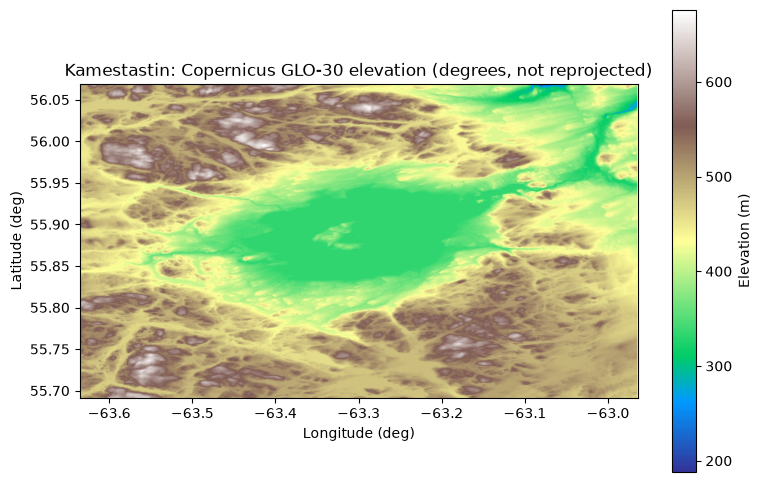

In [16]:
import matplotlib.pyplot as plt
import numpy as np

print("Missing (NaN) pixels:", int(np.isnan(dem).sum()))  # a DEM with holes would show up here

# Edges of the window in degrees, taken from the real grid: left = origin x, top = origin y, then add size x pixels
left = dem_transform.c
top = dem_transform.f
right = left + dem_transform.a * cols
bottom = top + dem_transform.e * rows   # e is negative, so this moves south

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(dem, extent=[left, right, bottom, top], cmap="terrain")  # extent places the image at its real lon/lat
fig.colorbar(im, ax=ax, label="Elevation (m)")  # colourbar shows which colour means which height
ax.set_title(f"{SITE_NAME}: Copernicus GLO-30 elevation (degrees, not reprojected)")
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
plt.show()

## Step 5: Reproject to a metre-based projection
**Why UTM zone 20N (EPSG:32620).** UTM measures in metres and keeps shapes true over a small area. Zone 20 covers longitudes -66 to -60, and our site (-63.3) is near its middle, so distortion over a 40 km window is tiny. UTM is also a standard that is easy to defend on a method page. A custom transverse Mercator centred exactly on the site would be a little more precise but harder to explain and to reuse for other sites. **Rerunning for another site:** the zone must change, so check the new longitude (zone = (lon + 180) // 6 + 1).

**Exact square window.** We read `MARGIN_KM` extra on every side in step 2, then build the output grid directly: a square centred on the site, `WINDOW_KM` wide, made of whole 30 m pixels. 40 km is 1333.3 pixels of 30 m, so the grid is 1333 x 1333 pixels (39.99 km). Because the extra margin covers the slight rotation of the UTM grid, there are no empty (NaN) corners. Earth and Moon windows can use the same size.


In [17]:
import matplotlib.pyplot as plt
import numpy as np
from pyproj import Transformer
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

TARGET_CRS = "EPSG:32620"  # UTM zone 20 north, in metres
PIXEL_M = 30               # 30 m matches the DEM's own resolution

# Site centre in UTM metres (always_xy=True means we pass longitude first, then latitude)
site_x, site_y = Transformer.from_crs("EPSG:4326", TARGET_CRS, always_xy=True).transform(CENTRE_LON, CENTRE_LAT)

n = round(WINDOW_KM * 1000 / PIXEL_M)  # whole pixels across the window (40 km / 30 m = 1333.3, rounded to 1333)
dst_h = dst_w = n
# Top-left corner is half the window west and north of the site, so the site sits exactly at the centre
dst_transform = from_origin(site_x - n * PIXEL_M / 2, site_y + n * PIXEL_M / 2, PIXEL_M, PIXEL_M)

dem_utm = np.full((dst_h, dst_w), np.nan, dtype="float32")  # empty grid; NaN would mark any place with no source data
reproject(
    source=dem, destination=dem_utm,
    src_transform=dem_transform, src_crs=dem_crs,
    dst_transform=dst_transform, dst_crs=TARGET_CRS,
    resampling=Resampling.bilinear,  # bilinear blends neighbouring pixels, which suits smooth elevation (nearest would look blocky)
    dst_nodata=np.nan,
)

print("New CRS:", TARGET_CRS)
print(f"Pixel size: {dst_transform.a:.1f} m east-west x {-dst_transform.e:.1f} m north-south")  # e is negative because rows run south
print(f"Grid shape: {dst_h} rows x {dst_w} columns = {dst_w * PIXEL_M / 1000:.2f} x {dst_h * PIXEL_M / 1000:.2f} km")
print("Pixels with no data (NaN):", int(np.isnan(dem_utm).sum()), "(should be 0)")
print(f"Elevation min / max: {np.nanmin(dem_utm):.1f} m / {np.nanmax(dem_utm):.1f} m  (before, with margin: {np.nanmin(dem):.1f} / {np.nanmax(dem):.1f})")

New CRS: EPSG:32620
Pixel size: 30.0 m east-west x 30.0 m north-south
Grid shape: 1333 rows x 1333 columns = 39.99 x 39.99 km
Pixels with no data (NaN): 0 (should be 0)
Elevation min / max: 273.3 m / 674.9 m  (before, with margin: 188.1 / 675.8)


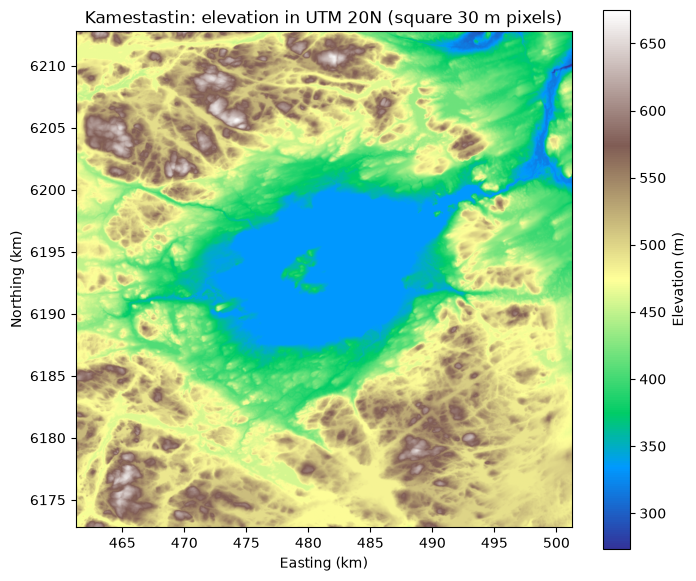

In [18]:
# Edges of the new grid in metres, converted to km for readable axes
x0 = dst_transform.c / 1000
x1 = (dst_transform.c + dst_transform.a * dst_w) / 1000
y1 = dst_transform.f / 1000
y0 = (dst_transform.f + dst_transform.e * dst_h) / 1000

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(dem_utm, extent=[x0, x1, y0, y1], cmap="terrain")  # 1 km on x is now the same length as 1 km on y
fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title(f"{SITE_NAME}: elevation in UTM 20N (square 30 m pixels)")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
plt.show()

**Lake count.** The lake is the largest flat area, so its surface elevation is the single most common value in the DEM. We count pixels at that value on the final grid, so the number quoted in step 6 is reproduced by the notebook.

In [19]:
values, counts = np.unique(dem, return_counts=True)  # every distinct elevation and how often it occurs
lake_level = values[counts.argmax()]                 # the most common elevation = the flat lake surface (assumes the lake is the biggest flat area)
lake_px = int(np.isclose(dem_utm, lake_level, atol=0.01).sum())  # tiny tolerance for float rounding after resampling
print(f"Lake surface: {lake_level:.1f} m")
print(f"Lake pixels on the final {dst_h} x {dst_w} grid: {lake_px:,}  ({100 * lake_px / dem_utm.size:.2f}% of the window)")
print(f"Lake area: {lake_px * PIXEL_M**2 / 1e6:.1f} km2")

Lake surface: 334.5 m
Lake pixels on the final 1333 x 1333 grid: 161,338  (9.08% of the window)
Lake area: 145.2 km2


**Save.** Writes the cropped UTM grid as a GeoTIFF into `data/processed/` so teammates can use it without rerunning this notebook. The file carries its own CRS and pixel-to-coordinate transform. Small processed outputs go here; large raw downloads stay out of git in `data/raw/`.

In [20]:
from pathlib import Path

# The notebook runs from /pipeline, so the repo root is one folder up
root = Path.cwd().parent if Path.cwd().name == "pipeline" else Path.cwd()
out_dir = root / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)  # create the folder if it does not exist yet
out_path = out_dir / f"{SITE_NAME.lower()}_dem_utm_{PIXEL_M}m.tif"

with rasterio.open(out_path, "w", driver="GTiff", height=dst_h, width=dst_w, count=1,
                   dtype="float32", crs=TARGET_CRS, transform=dst_transform, nodata=np.nan) as dst:
    dst.write(dem_utm, 1)  # band 1 = elevation in metres

with rasterio.open(out_path) as check:  # read it back to prove the file is correct
    print("Saved:", out_path.relative_to(root))  # relative path, so no personal folder names end up in the notebook
    print("CRS:", check.crs, "| shape:", check.shape, "| pixel size:", check.res, "| NaNs:", int(np.isnan(check.read(1)).sum()))

Saved: data\processed\kamestastin_dem_utm_30m.tif
CRS: EPSG:32620 | shape: (1333, 1333) | pixel size: (30.0, 30.0) | NaNs: 0


## Step 6: Your answers (before vs after reprojection)
*Write the answers yourself, in your own words. Reference numbers below come from our real run (steps 3, 5 and the lake check); change them if you rerun for another site.*

**Reference numbers:** before = EPSG:4326, 0.000417 x 0.000278 deg (1.50 x 1.00 arc-seconds), about 26.1 m east-west x 30.9 m north-south at the site centre, grid 1358 x 1611 (the 40 km window plus a 1 km read margin on each side). After = EPSG:32620 (UTM 20N), 30.0 x 30.0 m, exact square grid 1333 x 1333 (39.99 km), no NaNs. The lake is one constant value, 334.5 m, covering 161,338 pixels on the final grid (9.08% of the window, about 145.2 km2).

**1. What were the CRS and pixel size before reprojection?**

*Your answer:* Before reprojection, the DEM used EPSG:4326, a CRS based on longitude and latitude in degrees. Its pixels were 0.000417 x 0.000278 degrees (1.50 x 1.00 arc-seconds), which is about 26.1 m east-west by 30.9 m north-south at the site centre, on a 1358 x 1611 grid (40 km window plus 1 km read margin). After reprojection, it used EPSG:32620 (UTM zone 20N), which uses x and y coordinates in meters, with square 30 x 30 m pixels on a 1333 x 1333 grid (exactly the 40 km window, centred on the site).

**2. Why do the pixel sizes differ north-south versus east-west?**

*Your answer:* The pixel sizes differ because latitude and longitude are measured in degrees, which do not represent equal ground distances. One degree of latitude is always about 111 km, but one degree of longitude shrinks towards the poles by a factor of cos(latitude), so at 55.88 N it is only about 62 km. A pixel 1.5 arc-seconds wide is therefore about 26 m on the ground, narrower than a pixel 1 arc-second tall, which is about 31 m.

**3. What does the DEM record over the lake?**

*Your answer:* The DEM records one constant elevation of 334.5 m across the lake (161,338 pixels on the final 30 m grid, 9.08% of the selected window, about 145.2 km2), representing a flat water surface. Unlike the surrounding terrain, the lake shows no elevation variation at all, because its surface is stored as a single value. Note: the lake level and shape come from the provisional site centre and DEM; we have not yet checked the product documentation on why water bodies are flattened.
